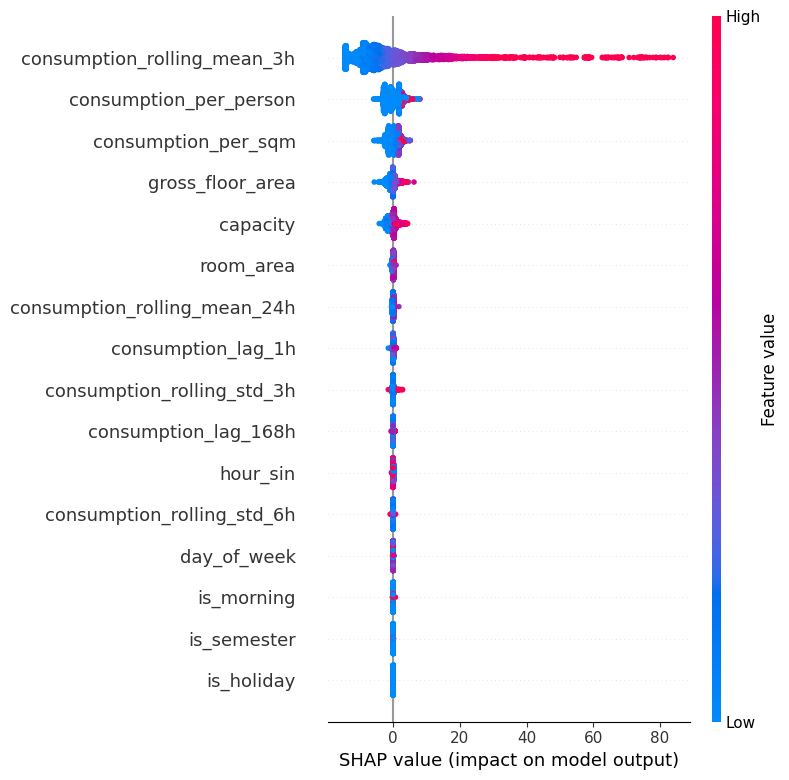

In [7]:
import joblib
import xgboost as xgb
import shap

# 1. Wczytanie parametrów XGBoost
best_params = joblib.load("models/xgb_best_params.pkl")

# 2. Wczytanie danych
X_train, X_test, y_train, y_test = joblib.load("models/data_for_shap.pkl")

# 3. Stwórz model NA NOWO i wytrenuj go
model = xgb.XGBRegressor(
    **best_params,
    n_estimators=300,
    tree_method="hist",
    eval_metric="rmse"
)
model.fit(X_train, y_train)  # <-- KLUCZOWE!

# 4. SHAP
X_test_sample = X_test.sample(n=5000, random_state=42)

explainer = shap.TreeExplainer(model)
shap_values = explainer(X_test_sample)

shap.summary_plot(shap_values.values, X_test_sample, feature_names=X_test_sample.columns)
